In [1]:
from ctypes import *

import os


import time

import matplotlib.pyplot as plt

import pyvisa

from scipy.optimize import curve_fit

import scipy.fft as fft

from Instruments.atsapi import *

from Routines.extraction_handling_pt import *

import shutil

In [49]:
floor1 = {}

floor2 = {}

floor3 = {}

floor4 = {}

folder1 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_downsampled_2026-02-22_16_59_26.771844"

folder2 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_downsampled_2026-02-22_19_45_39.858503"

folder3 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_downsampled_2026-02-22_22_31_49.144613"

folder4 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_downsampled_2026-02-23_11_31_26.417041"



for file in os.listdir(folder1):
    filepath = os.path.join(folder1, file)

    floor1[file] = measuredIQnoise(int(1E3), filepath)



for file in os.listdir(folder2):
    filepath = os.path.join(folder2, file)

    floor2[file] = measuredIQnoise(int(1E3), filepath)


for file in os.listdir(folder3):
    filepath = os.path.join(folder3, file)

    floor3[file] = measuredIQnoise(int(1E3), filepath)



for file in os.listdir(folder4):
    filepath = os.path.join(folder4, file)

    floor4[file] = measuredIQnoise(int(1E3), filepath)

for value in floor1.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

floor1_mag = []
floor1_phase= []

for value in floor1.values():
    floor1_mag.append(value.yf_mag)
    floor1_phase.append(value.yf_phase)


floor1_phase = np.array(np.average(floor1_phase, axis = 0))

for value in floor4.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

floor4_mag = []
floor4_phase= []

for value in floor4.values():
    floor4_mag.append(value.yf_mag)
    floor4_phase.append(value.yf_phase)

floor4_phase = np.array(np.average(floor4_phase, axis = 0))

for value in floor2.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

floor2_mag = []
floor2_phase= []

for value in floor2.values():
    floor2_mag.append(value.yf_mag)
    floor2_phase.append(value.yf_phase)


    
floor2_phase = np.array(np.average(floor2_phase, axis = 0))

for value in floor3.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

floor3_mag = []
floor3_phase= []

for value in floor3.values():
    floor3_mag.append(value.yf_mag)
    floor3_phase.append(value.yf_phase)

    
floor3_phase = np.array(np.average(floor3_phase, axis = 0))





True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


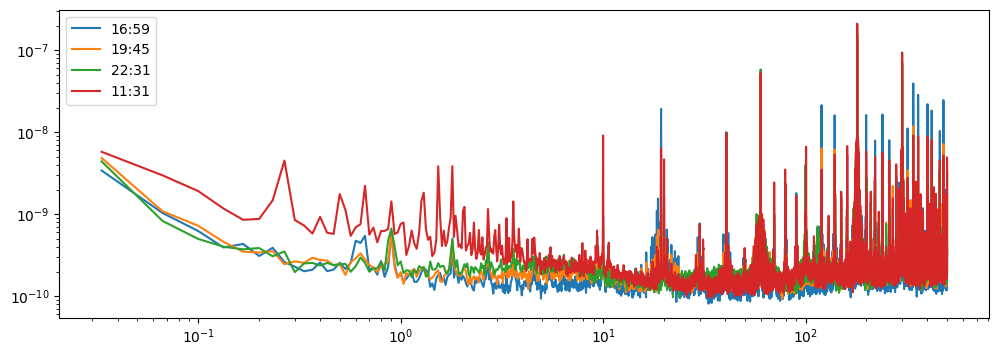

In [58]:
tag1 = folder1.split('_')[-3] + ':' + folder1.split('_')[-2]

tag2 = folder2.split('_')[-3] + ':' + folder2.split('_')[-2]

tag3 = folder3.split('_')[-3] + ':' + folder3.split('_')[-2]

tag4 = folder4.split('_')[-3] + ':' + folder4.split('_')[-2]

xf = floor1["0_downsampled.csv"].xf_phase

num_points = len(xf)

psd_floor1 = (floor1_phase**2)/(num_points*1E3)
psd_floor2 = (floor2_phase**2)/(num_points*1E3)
psd_floor3 = (floor3_phase**2)/(num_points*1E3)
psd_floor4 = (floor4_phase**2)/(num_points*1E3)
plt.figure(figsize = [12, 4])

plt.loglog(xf[1:], psd_floor1[1:], label = tag1)
plt.loglog(xf[1:], psd_floor2[1:], label = tag2)
plt.loglog(xf[1:], psd_floor3[1:], label = tag3)
plt.loglog(xf[1:], psd_floor4[1:], label = tag4)


plt.legend()
plt.show()

psd_floor = np.average([psd_floor1, psd_floor2, psd_floor3], axis=0)


In [59]:
neon1 = {}

neon2 = {}

neon3 = {}

neon4 = {}

folder1 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-21_10_47_58.227996"

folder2 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-21_14_21_35.637726"

folder3 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-21_15_39_59.215506"

folder4 = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_2026-02-21_18_26_13.416995"



for file in os.listdir(folder1):
    filepath = os.path.join(folder1, file)

    neon1[file] = measuredIQnoise(int(1E3), filepath)



for file in os.listdir(folder2):
    filepath = os.path.join(folder2, file)

    neon2[file] = measuredIQnoise(int(1E3), filepath)


for file in os.listdir(folder3):
    filepath = os.path.join(folder3, file)

    neon3[file] = measuredIQnoise(int(1E3), filepath)



for file in os.listdir(folder4):
    filepath = os.path.join(folder4, file)

    neon4[file] = measuredIQnoise(int(1E3), filepath)

for value in neon1.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

neon1_mag = []
neon1_phase= []

for value in neon1.values():
    neon1_mag.append(value.yf_mag)
    neon1_phase.append(value.yf_phase)


neon1_phase = np.array(np.average(neon1_phase, axis = 0))

for value in neon4.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

neon4_mag = []
neon4_phase= []

for value in neon4.values():
    neon4_mag.append(value.yf_mag)
    neon4_phase.append(value.yf_phase)

neon4_phase = np.array(np.average(neon4_phase, axis = 0))

for value in neon2.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

neon2_mag = []
neon2_phase= []

for value in neon2.values():
    neon2_mag.append(value.yf_mag)
    neon2_phase.append(value.yf_phase)


    
neon2_phase = np.array(np.average(neon2_phase, axis = 0))

for value in neon3.values():
    value.return_phase()
    value.return_magnitude()
    value.phase_fft()
    value.magnitude_fft()

neon3_mag = []
neon3_phase= []

for value in neon3.values():
    neon3_mag.append(value.yf_mag)
    neon3_phase.append(value.yf_phase)

    
neon3_phase = np.array(np.average(neon3_phase, axis = 0))





True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


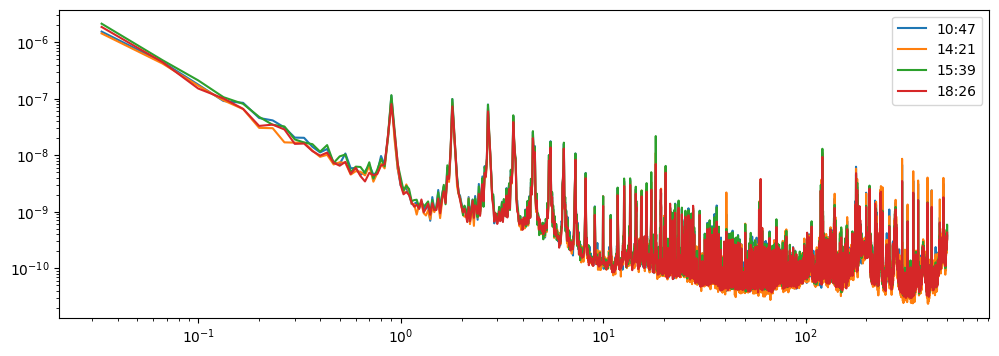

In [60]:
tag1 = folder1.split('_')[-3] + ':' + folder1.split('_')[-2]

tag2 = folder2.split('_')[-3] + ':' + folder2.split('_')[-2]

tag3 = folder3.split('_')[-3] + ':' + folder3.split('_')[-2]

tag4 = folder4.split('_')[-3] + ':' + folder4.split('_')[-2]

xf = neon1["0_downsampled.csv"].xf_phase

num_points = len(xf)

psd_neon1 = (neon1_phase**2)/(num_points*1E3)
psd_neon2 = (neon2_phase**2)/(num_points*1E3)
psd_neon3 = (neon3_phase**2)/(num_points*1E3)
psd_neon4 = (neon4_phase**2)/(num_points*1E3)
plt.figure(figsize = [12, 4])

plt.loglog(xf[1:], psd_neon1[1:], label = tag1)
plt.loglog(xf[1:], psd_neon2[1:], label = tag2)
plt.loglog(xf[1:], psd_neon3[1:], label = tag3)
plt.loglog(xf[1:], psd_neon4[1:], label = tag4)


plt.legend()
plt.show()


psd_neon = np.average([psd_neon1, psd_neon2, psd_neon3, psd_neon4], axis = 0)


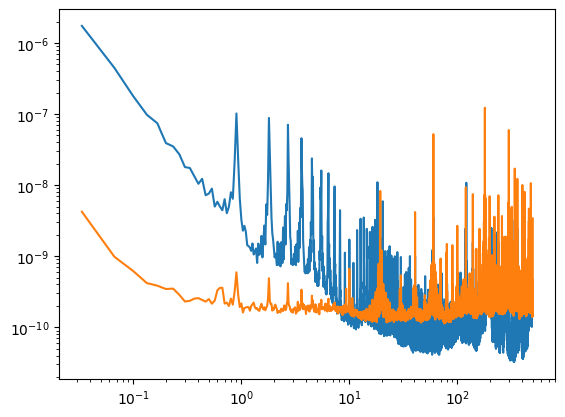

In [63]:

plt.loglog(xf[1:], psd_neon[1:])
plt.loglog(xf[1:], psd_floor[1:])

plt.show()

In [62]:
print(len(psd_floor))

15001
